# Statistical Analysis: Physiological Synchrony & Task Performance
This notebook conducts the statistical tests for the **Heart to Heart** experiment:
1. **Descriptive Statistics:** Per-condition means and standard deviations for synchrony and task performance.
2. **Research Question 1 (RQ1):** Wilcoxon signed-rank test comparing synchrony between **Haptics ON** and **Haptics OFF**.
3. **Research Question 2 (RQ2):** Spearman rank correlation assessing whether **synchrony predicts task score**.
4. **Secondary Checks:** Wilcoxon test on task performance scores and baseline heart rate controls.

## 1. Setup and Data Loading
Load synchrony scores, task performance counts, and the 1 Hz resampled heart rate dataset.

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, spearmanr
synchrony_data = pd.read_csv("synchrony_data.csv")
performance_data = pd.read_csv("performance_data.csv")
resampled_data = pd.read_csv("resampled_data.csv")

## 2. Descriptive Statistics
Calculate per-condition metrics (mean, standard deviation, and within-pair differences) for synchrony, puzzle score, and heart rate.

In [50]:
synchrony_on = synchrony_data[synchrony_data["phase"] == "hapticsON_task"].set_index("pair_id")["synchrony"]
synchrony_off = synchrony_data[synchrony_data["phase"] == "hapticsOFF_task"].set_index("pair_id")["synchrony"]

synchrony_comparison = pd.DataFrame({
    "pair_id": synchrony_on.index,
    "sync_ON": synchrony_on.values,
    "sync_OFF": synchrony_off.values,
    "difference": synchrony_on.values - synchrony_off.values,
})
print(synchrony_comparison)

    pair_id   sync_ON  sync_OFF  difference
0   pair_02 -0.148587  0.040923   -0.189510
1   pair_03 -0.095759  0.088562   -0.184321
2   pair_04  0.054634 -0.072786    0.127421
3   pair_05 -0.069878 -0.001788   -0.068090
4   pair_06 -0.050027  0.005614   -0.055641
5   pair_07 -0.005915  0.029722   -0.035638
6   pair_08  0.041290 -0.014045    0.055336
7  pilot_01 -0.079837 -0.088833    0.008996


In [51]:
performance_on = performance_data[performance_data["phase"] == "hapticsON_task"].set_index("pair_id")["blocks_correct"]
performance_off = performance_data[performance_data["phase"] == "hapticsOFF_task"].set_index("pair_id")["blocks_correct"]

performance_comparison = pd.DataFrame({
    "pair_id": performance_on.index,
    "perf_ON": performance_on.values,
    "perf_OFF": performance_off.values,
    "difference": performance_on.values - performance_off.values,
})
print(performance_comparison)

    pair_id  perf_ON  perf_OFF  difference
0  pilot_01       40        39           1
1   pair_02       52        40          12
2   pair_03       40        52         -12
3   pair_04       60        60           0
4   pair_05       22        46         -24
5   pair_06       23        20           3
6   pair_07       26        40         -14
7   pair_08       42        41           1


In [52]:
hr_by_pair = resampled_data.groupby(["pair_id", "phase"])["bpm"].mean().reset_index()
hr_by_pair = hr_by_pair.rename(columns={"bpm": "mean_hr"})

hr_on = hr_by_pair[hr_by_pair["phase"] == "hapticsON_task"].sort_values("pair_id")["mean_hr"].values
hr_off = hr_by_pair[hr_by_pair["phase"] == "hapticsOFF_task"].sort_values("pair_id")["mean_hr"].values

In [53]:
for label, series in [
    ("Synchrony ON", synchrony_on),
    ("Synchrony OFF", synchrony_off),
    ("Performance ON", performance_on),
    ("Performance OFF", performance_off),
]:
    print(f"{label}: mean = {series.mean():.3f}, SD = {series.std():.3f}")

Synchrony ON: mean = -0.044, SD = 0.070
Synchrony OFF: mean = -0.002, SD = 0.058
Performance ON: mean = 38.125, SD = 13.778
Performance OFF: mean = 42.250, SD = 11.597


In [54]:
baseline_sync = synchrony_data[synchrony_data["phase"] == "baseline"]["synchrony"]
print(f"Baseline: mean r = {baseline_sync.mean():.3f}, SD = {baseline_sync.std():.3f}, n = {len(baseline_sync)}")

Baseline: mean r = 0.004, SD = 0.044, n = 8


## 3. Research Question 1: Does Haptic Feedback Increase Physiological Synchrony?
- **Hypothesis:** Pairs receiving real-time tactile heartbeat feedback will exhibit higher physiological synchrony than in the control condition.
- **Statistical Test:** Non-parametric Wilcoxon signed-rank test (within-pairs repeated measures).

In [25]:
test_statistic, p_value = wilcoxon(synchrony_on, synchrony_off)
differences = synchrony_on.values - synchrony_off.values
number_of_nonzero_pairs = (differences != 0).sum()
effect_size = 1 - (2 * test_statistic) / (number_of_nonzero_pairs * (number_of_nonzero_pairs + 1) / 2)

print(f"Synchrony: W = {test_statistic}, p = {p_value:.4f}, r = {effect_size:.3f}, n = {number_of_nonzero_pairs}")
print(f"Haptics ON mean: {synchrony_on.mean():.4f}, Haptics OFF mean: {synchrony_off.mean():.4f}")

Synchrony: W = 10.0, p = 0.3125, r = 0.444, n = 8
Haptics ON mean: -0.0443, Haptics OFF mean: -0.0016


## 4. Secondary Check: Does Haptic Feedback Influence Task Performance?
- **Test:** Wilcoxon signed-rank test comparing puzzle scores (number of correct blocks) between **Haptics ON** and **Haptics OFF**.

In [45]:
test_statistic, p_value = wilcoxon(performance_on, performance_off)
differences = performance_on.values - performance_off.values
number_of_nonzero_pairs = (differences != 0).sum()
effect_size = 1 - (2 * test_statistic) / (number_of_nonzero_pairs * (number_of_nonzero_pairs + 1) / 2)

print(f"Performance: W = {test_statistic}, p = {p_value:.4f}, r = {effect_size:.3f}, n = {number_of_nonzero_pairs}")
print(f"Haptics ON mean: {performance_on.mean():.1f}, Haptics OFF mean: {performance_off.mean():.1f}")

Performance: W = 10.5, p = 0.6406, r = 0.250, n = 7
Haptics ON mean: 38.1, Haptics OFF mean: 42.2


## 5. Research Question 2: Does Physiological Synchrony Predict Task Performance?
- **Hypothesis:** Higher physiological synchrony across a session will correlate with better collaborative task success.
- **Statistical Test:** Spearman rank correlation ($\rho$) between mean synchrony ($r$) and blocks placed correctly (N=16 task sessions).

In [26]:
synchrony_with_performance = synchrony_data.merge(performance_data, on=["pair_id", "phase"])

correlation_coefficient, p_value = spearmanr(
    synchrony_with_performance["synchrony"],
    synchrony_with_performance["blocks_correct"]
)
print(f"Spearman: rho = {correlation_coefficient:.3f}, p = {p_value:.4f}, n = {len(synchrony_with_performance)}")

Spearman: rho = 0.193, p = 0.4742, n = 16


## 6. Control Check: Mean Heart Rate by Condition
Verify whether the haptic vibration altered overall autonomic arousal (mean heart rate in BPM) between conditions.

In [27]:
test_statistic, p_value = wilcoxon(hr_on, hr_off)
differences = hr_on - hr_off
number_of_nonzero_pairs = (differences != 0).sum()
effect_size = 1 - (2 * test_statistic) / (number_of_nonzero_pairs * (number_of_nonzero_pairs + 1) / 2)

print(f"Mean HR — ON: {hr_on.mean():.1f}, OFF: {hr_off.mean():.1f}")
print(f"Wilcoxon: W = {test_statistic}, p = {p_value:.4f}, r = {effect_size:.3f}")


Mean HR — ON: 81.8, OFF: 80.9
Wilcoxon: W = 17.0, p = 0.9453, r = 0.056


## 7. Statistical Visualisations
scatter plot summarizing the distribution of synchrony and performance across conditions.

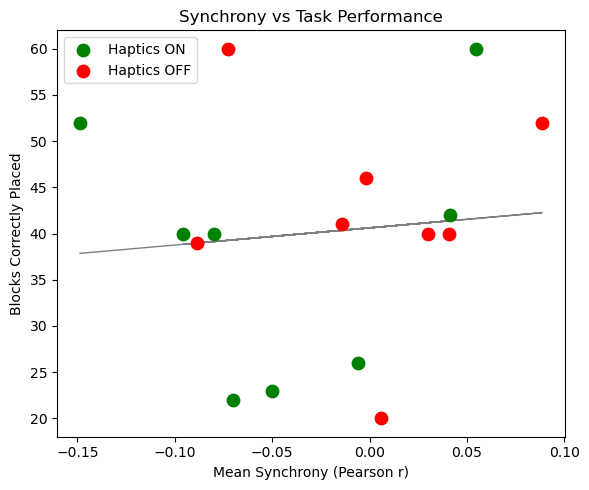

In [33]:
fig, ax = plt.subplots(figsize=(6, 5))

synchrony_with_performance = synchrony_data.merge(performance_data, on=["pair_id", "phase"])

for phase, colour, label in [("hapticsON_task", "green", "Haptics ON"),
                              ("hapticsOFF_task", "red", "Haptics OFF")]:
    subset = synchrony_with_performance[synchrony_with_performance["phase"] == phase]
    ax.scatter(subset["synchrony"], subset["blocks_correct"],
               color=colour, s=80, label=label, zorder=2)

    slope, intercept = np.polyfit(synchrony_with_performance["synchrony"],
                              synchrony_with_performance["blocks_correct"], 1)

ax.plot(synchrony_with_performance["synchrony"], slope * synchrony_with_performance["synchrony"] + intercept,
        color="grey", linewidth=1, zorder=1)
ax.set_xlabel("Mean Synchrony (Pearson r)")
ax.set_ylabel("Blocks Correctly Placed")
ax.set_title("Synchrony vs Task Performance")
ax.legend()
plt.tight_layout()
plt.savefig("fig_synchrony_vs_taskperformance.png", dpi=150)
plt.show()

Single pair heart-rate time series

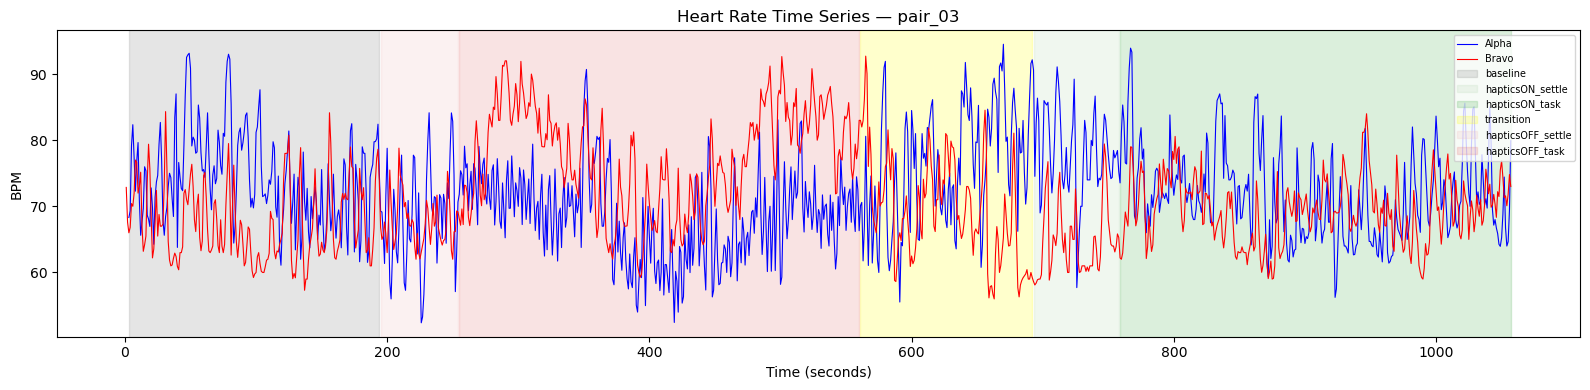

In [55]:
pair_to_plot = "pair_03"

pair_data = resampled_data[resampled_data["pair_id"] == pair_to_plot]
alpha_data = pair_data[pair_data["participant"] == "Alpha"].sort_values("time_s")
bravo_data = pair_data[pair_data["participant"] == "Bravo"].sort_values("time_s")

fig, ax = plt.subplots(figsize=(16, 4))

# Plot heart rates
ax.plot(alpha_data["time_s"], alpha_data["bpm"], label="Alpha", color="blue", linewidth=0.8)
ax.plot(bravo_data["time_s"], bravo_data["bpm"], label="Bravo", color="red", linewidth=0.8)

# Shade each phase
phase_colours = {
    "baseline": "grey",
    "hapticsON_settle": "#b6d7b3",
    "hapticsON_task": "#4caf50",
    "transition": "yellow",
    "hapticsOFF_settle": "#efbbbb",
    "hapticsOFF_task": "#e57373",
}

for phase_name, colour in phase_colours.items():
    phase_times = alpha_data[alpha_data["phase"] == phase_name]["time_s"]
    if not phase_times.empty:
        ax.axvspan(phase_times.min(), phase_times.max(), color=colour, alpha=0.2, label=phase_name)

ax.set_xlabel("Time (seconds)")
ax.set_ylabel("BPM")
ax.set_title(f"Heart Rate Time Series — {pair_to_plot}")
ax.legend(loc="upper right", fontsize=7)
plt.tight_layout()
plt.show()

All pairs heart rate time series

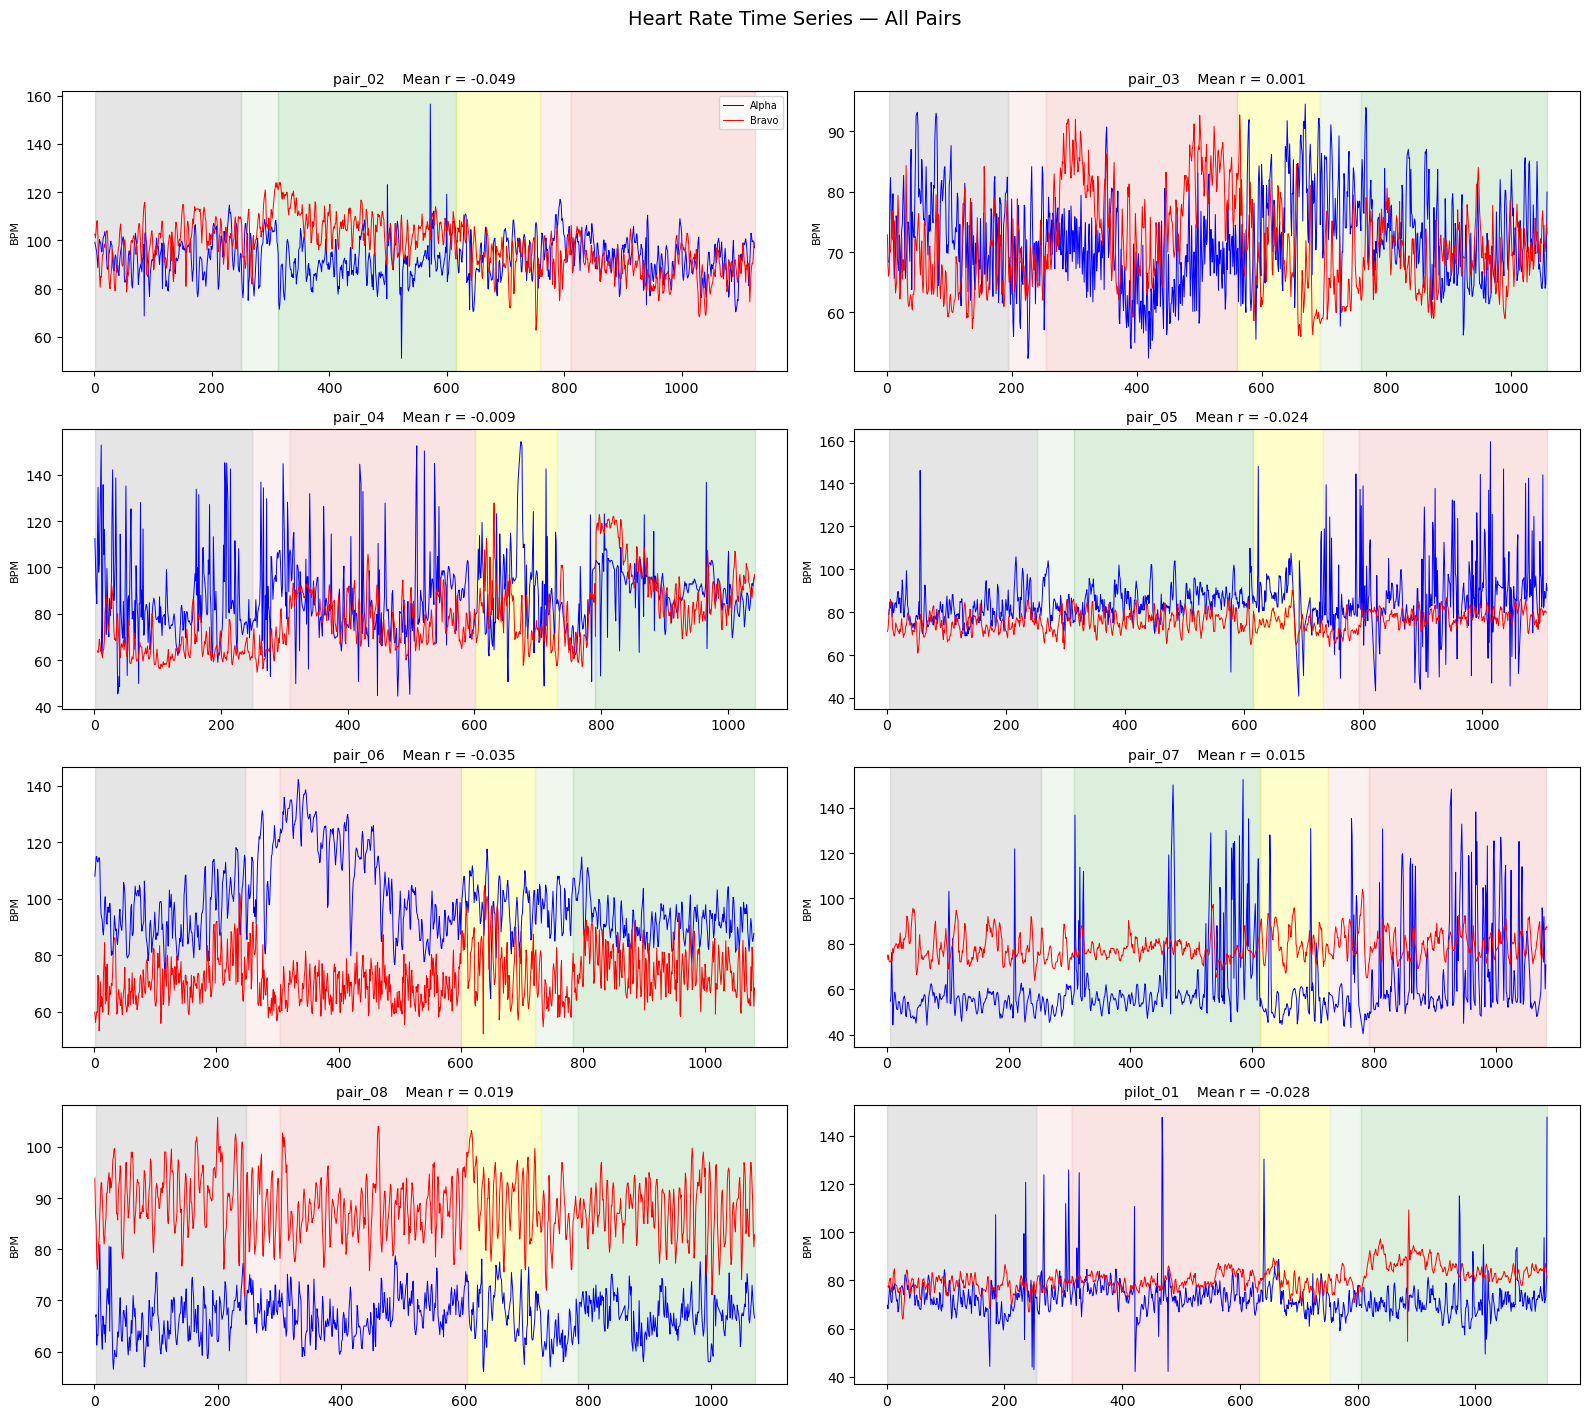

In [ ]:
pair_ids = sorted(resampled_data["pair_id"].unique())
number_of_pairs = len(pair_ids)
rows = 4
cols = 2

fig, axes = plt.subplots(rows, cols, figsize=(16, 14))
axes = axes.flatten()

for i, pair_id in enumerate(pair_ids):
    ax = axes[i]
    pair_data = resampled_data[resampled_data["pair_id"] == pair_id]
    alpha_data = pair_data[pair_data["participant"] == "Alpha"].sort_values("time_s")
    bravo_data = pair_data[pair_data["participant"] == "Bravo"].sort_values("time_s")

    # Get synchrony score for the title
    pair_sync = synchrony_data[synchrony_data["pair_id"] == pair_id]["synchrony"].mean()

    ax.plot(alpha_data["time_s"], alpha_data["bpm"], label="Alpha", color="blue", linewidth=0.7)
    ax.plot(bravo_data["time_s"], bravo_data["bpm"], label="Bravo", color="red", linewidth=0.7)

    # Phase shading
    phase_colours = {
        "baseline": "grey",
        "hapticsON_settle": "#b6d7b3",
        "hapticsON_task": "#4caf50",
        "transition": "yellow",
        "hapticsOFF_settle": "#efbbbb",
        "hapticsOFF_task": "#e57373",
    }

    for phase_name, colour in phase_colours.items():
        phase_times = alpha_data[alpha_data["phase"] == phase_name]["time_s"]
        if not phase_times.empty:
            ax.axvspan(phase_times.min(), phase_times.max(), color=colour, alpha=0.2)

    ax.set_title(f"{pair_id}    Mean r = {pair_sync:.3f}", fontsize=10)
    ax.set_ylabel("BPM", fontsize=8)

    if i == 0:
        ax.legend(fontsize=7, loc="upper right")


fig.suptitle("Heart Rate Time Series — All Pairs", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig("fig_timeseries_all_pairs.png", dpi=150, bbox_inches="tight")
plt.show()